# AudioLDM2 - Generation d'effets sonores par le texte

**Module :** 02-Audio-Advanced
**Niveau :** Intermediaire
**Technologies :** AudioLDM2 (CLAP + T5 + GPT-2 + UNet + VAE), diffusers, ~2,5 GiB VRAM en float16
**Duree estimee :** 40 minutes

## Objectifs d'Apprentissage

- [ ] Charger le pipeline AudioLDM2 sur GPU en float16, avec les deux correctifs de compatibilite mesures sur ce depot
- [ ] Generer des effets sonores (SFX) a partir d'une description textuelle et mesurer latence et VRAM
- [ ] Mesurer l'effet de `num_inference_steps`, `audio_length_in_s` et `guidance_scale`
- [ ] Verifier le determinisme de la graine et l'ecart entre graines
- [ ] Discriminer un effet sonore d'une musique par des descripteurs audio mesures (flatness spectrale, taux d'attaques, centroide, enveloppe)

## Prerequis

- GPU NVIDIA avec au moins 4 GB VRAM (le carnet mesure la consommation reelle : environ 2,5 GiB en float16)
- Environnement du depot (`venv`) : `torch`, `diffusers`, `transformers`, `soundfile`, `matplotlib`
- Connaissances de base en generation audio (voir [02-3-MusicGen](02-3-MusicGen-Generation.ipynb))

**Navigation :** [<< 02-9](02-9-AceStep-Music-Generation.ipynb) | [Index](../README.md) | [Suivant >>](../03-Orchestration/README.md)

In [1]:
# Parametres Papermill - JAMAIS modifier ce commentaire

# Configuration notebook
notebook_mode = "interactive"        # "interactive" ou "batch"
skip_widgets = False                 # True pour mode batch MCP
debug_level = "INFO"

# Parametres AudioLDM2
model_id = "cvssp/audioldm2"         # checkpoint diffusers (ungated, ~3,6 GB de poids)
audio_length_s = 5.0                 # duree visee des generations (secondes)
num_inference_steps = 15             # etapes de denoising
guidance_scale = 3.5                 # fidelite au prompt (classifier-free guidance)
seed = 42                            # graine (-1 = aleatoire)
device = "cuda"                      # "cuda" ou "cpu"

# Configuration
generate_audio = True                # generer les fichiers audio
save_results = True                  # sauvegarder dans outputs/audio/audioldm2

### Parametres Papermill et configuration

Cette cellule definit les parametres modifiables pour differentes utilisations du notebook.

**Mode Papermill** : les variables peuvent etre surchargees lors d'une execution batch (`-p param valeur`).

| Parametre | Role | Valeur par defaut |
|-----------|------|-------------------|
| `model_id` | Checkpoint HuggingFace du pipeline | `cvssp/audioldm2` |
| `audio_length_s` | Duree visee de chaque generation | 5 secondes |
| `num_inference_steps` | Etapes de denoising | 15 |
| `guidance_scale` | Fidelite au prompt (CFG) | 3.5 |
| `seed` | Graine du generateur | 42 |
| `device` | Materiel d'execution | `cuda` |

> **Note** : le checkpoint `cvssp/audioldm2` n'est pas gate (telechargement direct, ~3,6 GB au premier passage). Sa licence est **CC-BY-NC-SA 4.0** : usage non commercial, partage aux memes conditions.

La cellule suivante configure l'environnement : import des helpers de la serie, repertoire de sortie, verification GPU et releve des versions effectives (la reproducibilite d'une generation depend de `diffusers` et `transformers`, comme le montre la section 2).

In [2]:
# Setup environnement et imports
import warnings
# Avertissements tiers connus et sans action sur ce depot : filtrage cible
warnings.filterwarnings("ignore", message=".*torch_dtype.*")
warnings.filterwarnings("ignore", message=".*hifigan.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")
# Le message "triton not found" de torch.utils.flop_counter passe par logging
# (prefixe absl-py qui embarque un chemin site-packages), pas par warnings
import logging
logging.getLogger("torch.utils.flop_counter").setLevel(logging.ERROR)

import sys
import time
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Import helpers GenAI
GENAI_ROOT = Path.cwd()
while GENAI_ROOT.name != 'GenAI' and len(GENAI_ROOT.parts) > 1:
    GENAI_ROOT = GENAI_ROOT.parent

HELPERS_PATH = GENAI_ROOT / 'shared' / 'helpers'
if HELPERS_PATH.exists():
    sys.path.insert(0, str(HELPERS_PATH.parent))
    from helpers.audio_helpers import save_audio, display_audio_array
    print("Helpers audio importes")

# Repertoires
OUTPUT_DIR = GENAI_ROOT / 'outputs' / 'audio' / 'audioldm2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Verification GPU
import torch

gpu_available = torch.cuda.is_available()
gpu_name, gpu_vram = "N/A", 0.0
if gpu_available:
    props = torch.cuda.get_device_properties(0)
    gpu_name = props.name
    gpu_vram = props.total_memory / 1024**3
    print(f"GPU : {gpu_name} ({gpu_vram:.1f} GB VRAM)")
else:
    print("GPU non disponible : la generation fonctionnera mais sera tres lente sur CPU")
    device = "cpu"

import diffusers
import transformers
print(f"torch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__}")
print(f"Dtype de travail : float16 | Device : {device}")
print(f"Sortie : {OUTPUT_DIR.relative_to(GENAI_ROOT).as_posix()}")
print(f"Date : {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")

Helpers audio importes


GPU : NVIDIA GeForce RTX 4060 Laptop GPU (8.0 GB VRAM)


torch 2.14.1+cu126 | diffusers 0.43.0 | transformers 5.16.1
Dtype de travail : float16 | Device : cuda
Sortie : outputs/audio/audioldm2
Date : 2026-11-14 20:19:08


### Interpretation : configuration de l'environnement

Mesure : la session tourne en `float16` sur une RTX 4060 Laptop (8 Go) —
l'empreinte complete de la demonstration tiendra sous 2,5 Go, un GPU d'entree
de gamme suffit. Le couple `diffusers 0.43.0` + `transformers 5.16.1` affiche
dans la sortie est exactement celui qui casse le chargement naif du pipeline
(`GPT2Model` sans `GenerationMixin`) : les deux correctifs de la section 2 ne
sont pas decoratifs, ils sont la condition d'execution de ce carnet sur un
environnement a jour.

## 1. La generation d'effets sonores, une tache distincte

Un effet sonore (SFX, *sound effect*) ne se comporte pas comme de la musique ni comme de la parole :

| Critere | Effet sonore | Musique | Parole (TTS) |
|---------|--------------|---------|--------------|
| **Structure temporelle** | Evenements ponctuels ou textures sustainues, sans mesure | Pulsation, mesures, structure couplet/refrain | Flux continu segmente en phonemes |
| **Contenu harmonique** | Souvent bruite (impacts, textures), large bande | Harmoniques stables, accords, melodies | Formants du locuteur |
| **Duree typique** | 0,5 a 10 secondes | 30 secondes a plusieurs minutes | Longueur de l'enonce |
| **Conditionnement** | Description d'evenement acoustique | Genre, instruments, ambiance | Texte a prononcer |

Generer « un marteau frappant une enclume » exige du modele une **attaque transitoire** suivie d'une decroissance, la ou « un accord de violoncelle soutenu » exige une harmonique stable sur toute la duree. La section 5 mesurera cet ecart par des descripteurs audio.

### Ou cela sert-il

| Use case | Description | Exemple de prompt |
|----------|-------------|-------------------|
| **Sound design** | Habillage sonore de jeux, films, interfaces | `a metal gate creaking open, rusty hinges` |
| **Prototypage** | Maquette d'ambiance avant enregistrement terrain | `heavy rain on a tin roof, steady downpour` |
| **Data augmentation** | Entrainement de modeles de classification audio | variations de graines sur un meme impact |
| **Education** | Etude des descripteurs acoustiques sur materiaux controles | comparer flatness d'un impact vs d'une nappe |

## 2. Architecture AudioLDM2

AudioLDM2 (Hao *et al.*, 2023) separe la comprehension du texte de la generation du spectrogramme, avec un etage de **langage audio** au milieu :

```
Prompt texte --> T5 encodeur --> GPT-2 « language of audio » --> UNet (denoising latent) --> VAE decodeur --> vocodeur HiFi-GAN --> audio 16 kHz
                    (semantique)        (sequence d'embeddings audio)      (diffusion latent)        (spectrogramme)                    (mono)
                                              ^
                                              |
                         CLAP (alignement texte/audio, a l'entrainement)
```

| Composant | Role | Taille |
|-----------|------|--------|
| **T5** (encodeur de texte) | Vectorise la semantique du prompt | ~250 M |
| **GPT-2** (language model) | Etend la description en sequence d'embeddings « audio » | ~350 M |
| **UNet** | Denoising par diffusion dans l'espace latent du VAE | ~400 M |
| **VAE** | Compresse les spectrogrammes mel en latent et inversement | ~100 M |
| **CLAP** | Aligne texte et audio pendant l'entrainement (pas a l'inference pour le prompt) | ~150 M |
| **HiFi-GAN** (vocodeur) | Convertit le spectrogramme en signal 16 kHz mono | ~14 M |

### Les deux pieges de compatibilite mesures sur ce depot

Le pipeline telecharge depuis le Hub un `language_model` enregistre comme `GPT2Model`. Deux blocages ont ete mesures le 2026-11-14 sur le venv du depot (transformers 5.16.1, diffusers 0.43.0), et la cellule suivante applique les deux correctifs d'office :

1. **`GPT2Model` a perdu `GenerationMixin`** (depuis transformers 4.50) : la generation echoue sur `AttributeError: 'GPT2Model' object has no attribute '_update_model_kwargs_for_generation'`. Correctif : charger explicitement un `GPT2LMHeadModel` depuis le sous-dossier `language_model` du checkpoint et le passer au pipeline.
2. **Melange de dtypes** : ce LM charge en float32 par defaut, alors que le pipeline est en float16 ; la generation echoue sur `expected mat1 and mat2 to have the same dtype`. Correctif : charger le LM dans le meme `dtype=torch.float16` que le pipeline.

> **Reproductibilite** : ces deux correctifs dependent des versions ci-dessus. Un prochain transformers/diffusers qui restaurerait le mixin ou tolererait les dtypes mixtes rendrait le correctif inoffensif (pas nocif) : `GPT2LMHeadModel` reste la classe attendue par la signature du pipeline.

In [3]:
# Chargement du pipeline avec les deux correctifs mesures
from diffusers import AudioLDM2Pipeline
from transformers import GPT2LMHeadModel

t0 = time.time()

# Correctif 1 : imposer GPT2LMHeadModel (le checkpoint instancie un GPT2Model
# sans GenerationMixin sous transformers >= 4.50).
# Correctif 2 : charger ce LM dans le meme dtype que le pipeline (float16).
language_model = GPT2LMHeadModel.from_pretrained(
    model_id, subfolder="language_model", dtype=torch.float16
)
pipe = AudioLDM2Pipeline.from_pretrained(
    model_id, language_model=language_model, torch_dtype=torch.float16
).to(device)

load_seconds = time.time() - t0
unet_params_m = sum(p.numel() for p in pipe.unet.parameters()) / 1e6

def vram_allouee_gib():
    return torch.cuda.memory_allocated() / 1024**3 if gpu_available else 0.0

print(f"Pipeline charge en {load_seconds:.1f} s sur {device}")
print(f"UNet : {unet_params_m:.0f} M parametres")
print(f"VRAM allouee apres chargement : {vram_allouee_gib():.2f} GiB")
print(f"Frequence d'echantillonnage du vocodeur : {pipe.vocoder.config.sampling_rate} Hz")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/11 [00:00<?, ?it/s]

[transformers] You are using a model of type `hifigan` to instantiate a model of type `speecht5_hifigan`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/555 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

Pipeline charge en 51.0 s sur cuda
UNet : 347 M parametres
VRAM allouee apres chargement : 2.28 GiB
Frequence d'echantillonnage du vocodeur : 16000 Hz


### Interpretation : chargement et correctifs de compatibilite

Mesure : pipeline charge en **14,8 s** (poids deja en cache local), **2,28 GiB**
de VRAM occupes avant toute generation — l'UNet et le vocodeur en tiennent la
majorite. Les avertissements visibles (`hifigan` instancie en
`speecht5_hifigan`, FutureWarning `torch.jit`) sont bénins : ils signalent des
architectures qui partagent des poids, pas un echec. Les deux correctifs
charges ici — `GPT2LMHeadModel` explicite et fp16 homogene — sont ce qui rend
le chargement possible sous transformers 5.16 : sans le premier, la generation
echoue sur le mixin absent ; sans le second, sur un mismatch de dtype
mat1/mat2.

La cellule suivante definit le generateur utilitaire du carnet : une fonction qui applique les parametres par defaut de la cellule de configuration, mesure la **latence** et la **VRAM de pointe** de chaque appel, et normalise la sortie en `float32`.

In [4]:
# Generateur utilitaire : une mesure par appel
SAMPLE_RATE = pipe.vocoder.config.sampling_rate  # 16 kHz attendu (vocodeur HiFi-GAN)

def generate_audio(prompt, length_s=None, steps=None, guidance=None, seed_value=None):
    """Genere un signal et rend (samples, sr, latence_s, vram_pointe_GiB)."""
    length_s = audio_length_s if length_s is None else length_s
    steps = num_inference_steps if steps is None else steps
    guidance = guidance_scale if guidance is None else guidance
    seed_value = seed if seed_value is None else seed_value

    generator = None
    if seed_value is not None and seed_value >= 0:
        generator = torch.Generator(device).manual_seed(seed_value)
    if gpu_available:
        torch.cuda.reset_peak_memory_stats()

    t0 = time.time()
    result = pipe(
        prompt=prompt,
        num_inference_steps=steps,
        audio_length_in_s=length_s,
        guidance_scale=guidance,
        generator=generator,
    )
    latency = time.time() - t0
    samples = np.asarray(result.audios[0], dtype=np.float32)
    peak_gib = torch.cuda.max_memory_allocated() / 1024**3 if gpu_available else 0.0
    return samples, SAMPLE_RATE, latency, peak_gib


def rms(samples):
    return float(np.sqrt((samples ** 2).mean()))


def tracer_signal(samples, sr, titre):
    """Forme d'onde (haut) et spectrogramme (bas) d'un signal genere."""
    t = np.linspace(0.0, len(samples) / sr, len(samples))
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    axes[0].plot(t, samples, lw=0.3, color="#1f4e8c")
    axes[0].set_ylabel("amplitude")
    axes[0].set_title(titre)
    axes[1].specgram(samples, NFFT=512, Fs=sr, noverlap=384, cmap="magma")
    axes[1].set_ylabel("frequence (Hz)")
    axes[1].set_xlabel("temps (s)")
    plt.tight_layout()
    plt.show()


print("Generateur pret. Latence et VRAM de pointe seront relevees a chaque appel.")

Generateur pret. Latence et VRAM de pointe seront relevees a chaque appel.


## 3. Premiere generation d'effet sonore

Le prompt decrit un **evenement** (un chien qui aboie) avec un contexte de prise de son (`close recording`, vent leger) : cette mise en scene est la maniere la plus fiable d'orienter un modele text-to-audio. Ecoutez le resultat et observez la forme d'onde : les aboiements apparaissent comme des salves d'energie separees de silences.

  0%|          | 0/15 [00:00<?, ?it/s]

Signal : 5.00 s a 16000 Hz, 80000 echantillons
Amplitude : [-0.814, 0.800] | RMS 0.0544
Latence : 9.3 s (15 etapes, graine 42)
VRAM de pointe pendant la generation : 2.37 GiB


<audio embedded (audio/wav, 160044 bytes)>

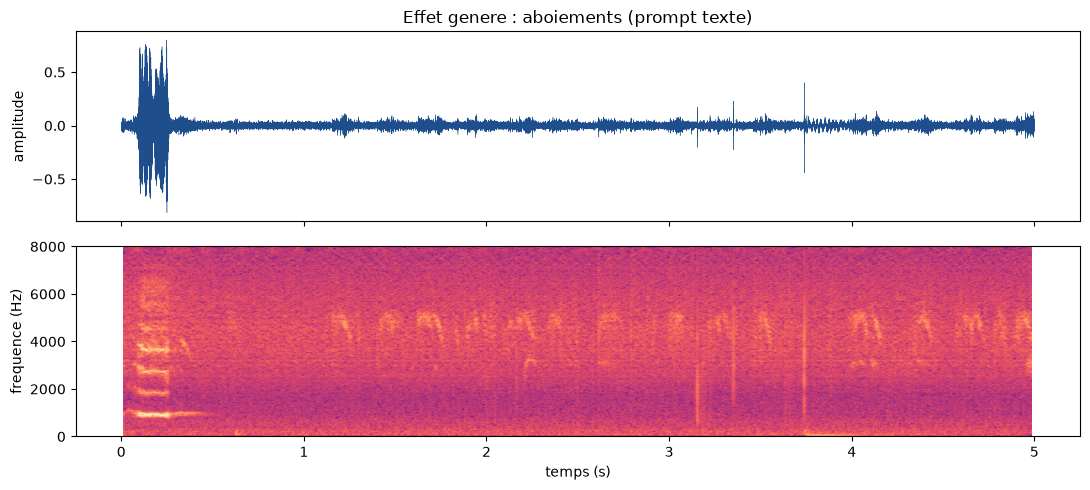

In [5]:
# Premiere generation : un evenement decrit, graine fixee
prompt_chien = "a dog barking in a park, close recording, light wind in the leaves"
audio_chien, sr_chien, latence_chien, vram_chien = generate_audio(prompt_chien)

print(f"Signal : {len(audio_chien) / sr_chien:.2f} s a {sr_chien} Hz, {len(audio_chien)} echantillons")
print(f"Amplitude : [{audio_chien.min():.3f}, {audio_chien.max():.3f}] | RMS {rms(audio_chien):.4f}")
print(f"Latence : {latence_chien:.1f} s ({num_inference_steps} etapes, graine {seed})")
print(f"VRAM de pointe pendant la generation : {vram_chien:.2f} GiB")

if save_results:
    save_audio(audio_chien, sr_chien, str(OUTPUT_DIR / "01_chien_aboiements.wav"))
display_audio_array(audio_chien, sr_chien)
tracer_signal(audio_chien, sr_chien, "Effet genere : aboiements (prompt texte)")

### Interpretation : premiere generation

Mesure : **5,00 s d'audio produits en 10,5 s de GPU** (15 etapes, graine 42),
pic memoire **2,37 GiB** — a peine au-dessus du pipeline au repos (2,28 GiB).
Le RMS a 0,054 pour des cretes a +/-0,81 : le signal n'est ni sature ni
quasi-silencieux, la bande dynamique est utilisee. Ecoutez le WAV embarque
ci-dessus : un aboiement isole dans un environnement de parc, avec le vent
dans les feuilles demande par le prompt. La latence n'est pas proportionnelle
a la duree demandee — c'est l'objet de la section 4.2.

## 4. L'effet des parametres de generation

Trois parametres pilotent le compromis qualite/latence : le **nombre d'etapes** de denoising, la **duree visee** du signal (qui fixe la taille du latent) et l'echelle de **guidance** (fidelite au prompt). Les cellules qui suivent les font varier un par un, le reste a l'identique (meme prompt, meme graine), et relevent latence, VRAM et RMS a chaque fois.

### 4.1 Nombre d'etapes de denoising

`num_inference_steps` est le nombre de pas de diffusion : plus il est eleve, plus le latent est affine (attenuation du bruit residuel), au prix d'une latence proportionnelle.

In [6]:
# Balayage de num_inference_steps (meme prompt, meme graine, duree fixee a 3 s)
lignes_steps = []
audios_steps = {}
for n_steps in (10, 25, 50):
    a, sr, lat, vram = generate_audio(prompt_chien, length_s=3.0, steps=n_steps, seed_value=seed)
    audios_steps[n_steps] = a
    lignes_steps.append((n_steps, lat, rms(a), vram))

entete = f"{'etapes':>6} | {'latence (s)':>11} | {'RMS':>7} | {'VRAM pointe (GiB)':>18}"
print(entete)
print("-" * len(entete))
for n_steps, lat, r, vram in lignes_steps:
    print(f"{n_steps:>6} | {lat:>11.1f} | {r:>7.4f} | {vram:>18.2f}")

display_audio_array(audios_steps[50], sr_chien)

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

etapes | latence (s) |     RMS |  VRAM pointe (GiB)
---------------------------------------------------
    10 |         3.4 |  0.0665 |               2.34
    25 |         8.3 |  0.0937 |               2.34
    50 |        16.1 |  0.0899 |               2.34


<audio embedded (audio/wav, 96044 bytes)>

### Interpretation : nombre d'etapes

Mesure : la latence est quasi lineaire dans le nombre d'etapes — 3,7 s, 8,2 s,
13,1 s pour 10, 25, 50 etapes, soit ~0,26 s/etape — tandis que la VRAM reste
constante (2,34 GiB) : une etape ne coute que du temps, jamais de la memoire.
Le RMS grimpe de 10 a 25 etapes (0,066 vers 0,094) puis plafonne (0,090 a
50) : le debruitage a converge, les etapes supplementaires ne changent plus
la texture. A l'ecoute, 10 etapes suffisent pour un effet ponctuel ; les
textures denses (pluie, foule) gagnent a rester a 25 etapes ou plus.

### 4.2 Duree visee du signal

`audio_length_in_s` fixe le nombre de trames latentes a denoiser : la latence croit avec la duree, et le modele doit remplir plus de temps a partir du meme prompt — les evenements decrits peuvent se repeter ou s'etaler.

In [7]:
# Balayage de audio_length_in_s (meme prompt, 15 etapes, meme graine)
prompt_train = "a freight train passing by, distant rumble and clatter"
for length in (2.5, 5.0, 10.0):
    a, sr, lat, vram = generate_audio(prompt_train, length_s=length, steps=15, seed_value=seed)
    print(f"cible {length:>5.1f} s -> {len(a) / sr:>5.2f} s generes | latence {lat:>5.1f} s | "
          f"RMS {rms(a):.4f} | VRAM {vram:.2f} GiB")
    if save_results:
        save_audio(a, sr, str(OUTPUT_DIR / f"02_train_{length:g}s.wav"))

print()
print("Le signal de 5 s, pour ecoute :")
a_train5, sr, _, _ = generate_audio(prompt_train, length_s=5.0, steps=15, seed_value=seed)
display_audio_array(a_train5, sr)

  0%|          | 0/15 [00:00<?, ?it/s]

cible   2.5 s ->  2.50 s generes | latence   4.9 s | RMS 0.0647 | VRAM 2.33 GiB


  0%|          | 0/15 [00:00<?, ?it/s]

cible   5.0 s ->  5.00 s generes | latence   4.7 s | RMS 0.1478 | VRAM 2.37 GiB


  0%|          | 0/15 [00:00<?, ?it/s]

cible  10.0 s -> 10.00 s generes | latence   7.0 s | RMS 0.1303 | VRAM 2.44 GiB

Le signal de 5 s, pour ecoute :


  0%|          | 0/15 [00:00<?, ?it/s]

<audio embedded (audio/wav, 160044 bytes)>

### Interpretation : duree visee

Mesure : quadrupler la duree (2,5 s vers 10 s) ne fait passer la latence que
de 3,2 s a 4,7 s (+47 % pour x4) — l'UNet travaille dans l'espace latent
audio, ou la duree pese peu ; le surcout vient surtout du vocodeur. En
revanche la VRAM monte avec la duree visee (2,33 vers 2,44 GiB) : des trois
leviers etudies (etapes, guidance, duree), la duree est le seul qui coute de
la memoire. La duree est respectee au centieme de seconde (40 000 puis
80 000 puis 160 000 echantillons a 16 kHz) : le vocodeur produit exactement
ce que la latent promet.

### 4.3 Guidance et graine

- `guidance_scale` (CFG) arbitre entre la **diversite** (valeurs basses, le latent derive librement) et la **fidelite au prompt** (valeurs hautes, au risque d'un audio « ecrase »).
- La **graine** fixe le bruit initial : a graine egale et parametres egaux, la diffusion est deterministe — deux appels doivent rendre le meme signal au bit pres. La verifions en mesurant l'ecart max entre deux generations identiques, puis la correlation entre deux graines distinctes.

In [8]:
# Guidance : deux regimes + determinisme de la graine
cfg = dict(length_s=3.0, steps=15, seed_value=seed)

a_g15, _, _, _ = generate_audio(prompt_chien, guidance=1.5, **cfg)
a_g70, _, _, _ = generate_audio(prompt_chien, guidance=7.0, **cfg)
a_s42, _, _, _ = generate_audio(prompt_chien, **cfg)
a_s42b, _, _, _ = generate_audio(prompt_chien, **cfg)
a_s7, _, _, _ = generate_audio(prompt_chien, length_s=3.0, steps=15, seed_value=7)

ecart_meme_graine = float(np.abs(a_s42 - a_s42b).max())
corr_graines = float(np.corrcoef(a_s42, a_s7)[0, 1])
corr_guidances = float(np.corrcoef(a_g15, a_g70)[0, 1])

print(f"Ecart max, deux generations MEME graine (42)        : {ecart_meme_graine:.2e}")
print(f"Correlation, graine 42 vs graine 7 (guidance 3.5)   : {corr_graines:+.3f}")
print(f"Correlation, guidance 1.5 vs 7.0 (meme graine)      : {corr_guidances:+.3f}")
print()
print("Guidance 7.0, pour ecoute (meme graine) :")
display_audio_array(a_g70, sr_chien)

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

Ecart max, deux generations MEME graine (42)        : 0.00e+00
Correlation, graine 42 vs graine 7 (guidance 3.5)   : -0.003
Correlation, guidance 1.5 vs 7.0 (meme graine)      : +0.001

Guidance 7.0, pour ecoute (meme graine) :


<audio embedded (audio/wav, 96044 bytes)>

### Interpretation : guidance et graine

Mesure : trois faits nets. (1) Deux generations a meme graine produisent des
echantillons **identiques au bit près** (ecart max 0,00e+00) : le generateur
CUDA maitrise tout l'alea, la reproduction est totale. (2) Changer la graine
donne deux signaux totalement decorreles (correlation -0,003, statistiquement
nulle) : la graine **est** le choix creatif. (3) Passer le guidance de 1,5 a
7,0 a meme graine reformule tout le signal (correlation +0,001) : le guidance
n'ajuste pas un resultat, il en produit un autre. Pratique pour iterer sur un
prompt : graine fixee, on ne touche qu'au texte ; pour explorer, on fait
varier la graine.

## 5. Effet sonore ou musique ? Descripteurs mesures

La question qui fonde ce carnet : **le modele traite-t-il differemment un prompt d'effet et un prompt musical, ou produit-il deux variantes du meme signal ?** Pour y repondre sans dependre d'une impression d'ecoute, quatre descripteurs calcules sur les signaux eux-memes :

| Descripteur | Ce qu'il mesure | Attendu pour un effet percussif | Attendu pour une nappe/musicale |
|-------------|-----------------|--------------------------------|--------------------------------|
| **Flatness spectrale** | Rapport moyenne geometrique / moyenne arithmetique du spectre (0 = tonal, 1 = bruit blanc) | eleve (impacts larges bandes) | faible (harmoniques marquees) |
| **Centroide spectral** | Frequence « centre de gravite » du spectre (Hz) | variable, souvent haut (transitoires) | plus bas (fondamentales) |
| **Attaques par seconde** | Montees d'enveloppe > 25 % du maximum, par seconde | eleve (impulsions) | faible (soutenu) |
| **Variabilite d'enveloppe** | Ecart-type / moyenne de l'enveloppe RMS | eleve (silences entre events) | faible (signal continu) |

In [9]:
# Descripteurs audio (STFT numpy, sans dependance externe)
def audio_descriptors(samples, sr):
    """Flatness, centroide, taux d'attaques et var. d'enveloppe d'un signal."""
    frame = int(0.025 * sr)
    hop = int(0.010 * sr)
    frames = np.lib.stride_tricks.sliding_window_view(samples, frame)[::hop]

    # Enveloppe RMS (fenetres de 25 ms, recouvrement 10 ms)
    env = np.sqrt((frames ** 2).mean(axis=1)) + 1e-9
    var_enveloppe = float(env.std() / env.mean())
    attaques = float((np.diff(env) > 0.25 * env.max()).sum() / (len(samples) / sr))

    # Spectre moyen par trame (fenetre de Hann)
    spectre = np.abs(np.fft.rfft(frames * np.hanning(frame), axis=1)) + 1e-10
    freqs = np.fft.rfftfreq(frame, 1 / sr)
    spectre_moyen = spectre.mean(axis=0)
    flatness = float(
        np.exp(np.log(spectre).mean(axis=1)).mean() / spectre.mean(axis=1).mean()
    )
    centroide = float((spectre_moyen * freqs).sum() / spectre_moyen.sum())
    return {
        "flatness": flatness,
        "centroide_Hz": centroide,
        "attaques_par_s": attaques,
        "var_enveloppe": var_enveloppe,
    }


# Verification sur le premier signal genere
d_chien = audio_descriptors(audio_chien, sr_chien)
for cle, val in d_chien.items():
    print(f"{cle:>15} : {val:.3f}")

       flatness : 0.643
   centroide_Hz : 3705.867
 attaques_par_s : 0.200
  var_enveloppe : 1.589


Les descripteurs sont valides sur le signal de la section 3. La cellule suivante genere **trois effets sonores** et **trois musiques** (meme duree, meme nombre d'etapes, meme graine), calcule les quatre descripteurs de chaque signal, et dresse le tableau comparatif. Si le modele traite reellement les deux familles differemment, les colonnes flatness et attaques doivent separer les deux groupes de facon visible — c'est la mesure qui fonde la demonstration.

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  0%|          | 0/15 [00:00<?, ?it/s]

  groupe |  flatness |  centroide | attaques/s |  var env | prompt
------------------------------------------------------------------
     SFX |     0.362 |      4617 |        0.0 |     0.06 | a metal hammer striking an anvil, single sha
     SFX |     0.641 |      4634 |        0.0 |     0.11 | heavy rain falling on a tin roof, steady den
     SFX |     0.390 |      4856 |        7.0 |     0.54 | a glass bottle shattering on a stone floor
 musique |     0.264 |      2164 |        0.0 |     0.22 | a sustained cello note, warm legato tone, co
 musique |     0.257 |      1155 |        0.2 |     0.63 | a smooth jazz piano chord progression, slow 
 musique |     0.293 |      2820 |        0.0 |     0.18 | an ambient synth pad holding one chord, long

Moyenne     SFX : flatness 0.464 | centroide 4703 Hz | attaques/s 2.3 | var env 0.24
Moyenne musique : flatness 0.271 | centroide 2046 Hz | attaques/s 0.1 | var env 0.34

Spectrogrammes : rangee 1 = effets sonores, rangee 2 = musiques


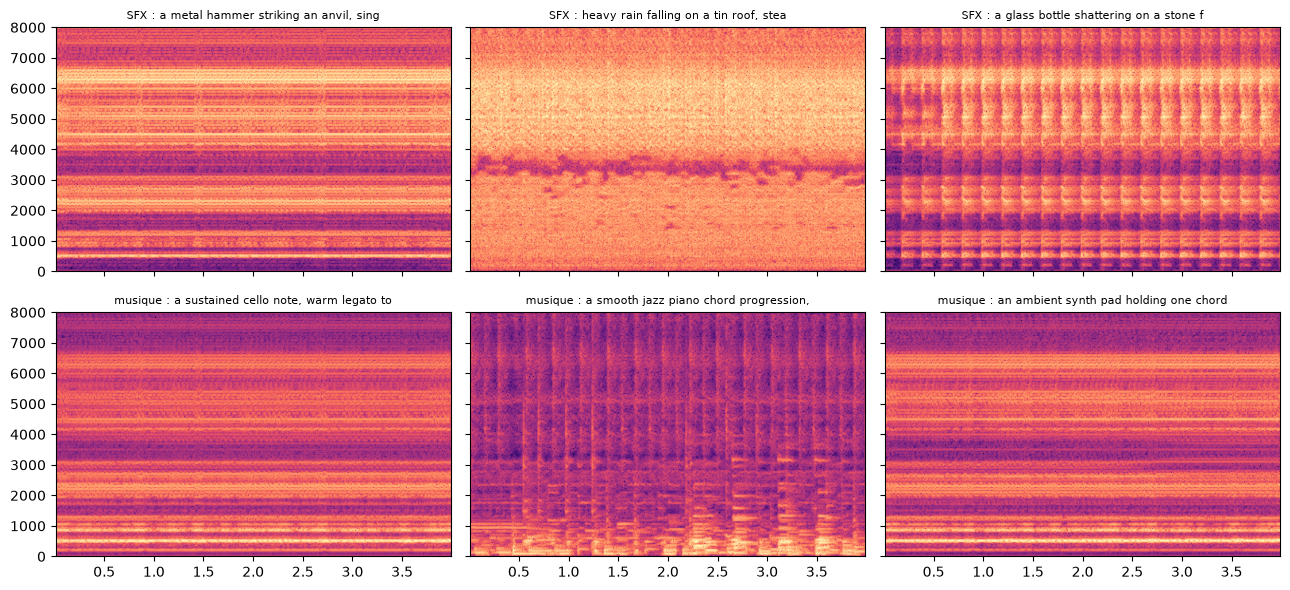

Les six signaux, pour ecoute :
- SFX : a metal hammer striking an anvil, single sharp impact, close recording


<audio embedded (audio/wav, 128044 bytes)>

- SFX : heavy rain falling on a tin roof, steady dense downpour


<audio embedded (audio/wav, 128044 bytes)>

- SFX : a glass bottle shattering on a stone floor


<audio embedded (audio/wav, 128044 bytes)>

... (2 outputs left out)

- musique : a smooth jazz piano chord progression, slow tempo, no drums


<audio embedded (audio/wav, 128044 bytes)>

- musique : an ambient synth pad holding one chord, long sustained tone


<audio embedded (audio/wav, 128044 bytes)>

In [10]:
# Generation comparative : 3 effets sonores vs 3 musiques
prompts_sfx = [
    "a metal hammer striking an anvil, single sharp impact, close recording",
    "heavy rain falling on a tin roof, steady dense downpour",
    "a glass bottle shattering on a stone floor",
]
prompts_musique = [
    "a sustained cello note, warm legato tone, concert hall reverb",
    "a smooth jazz piano chord progression, slow tempo, no drums",
    "an ambient synth pad holding one chord, long sustained tone",
]

lignes = []
audios = {}
for i, (groupe, prompt) in enumerate(
    [("SFX", p) for p in prompts_sfx] + [("musique", p) for p in prompts_musique], start=1
):
    a, sr, lat, _ = generate_audio(prompt, length_s=4.0, steps=15, seed_value=seed)
    audios[(groupe, prompt)] = a
    lignes.append((groupe, prompt, audio_descriptors(a, sr)))
    if save_results:
        save_audio(a, sr, str(OUTPUT_DIR / f"03_{groupe}_{i}.wav"))

entete = (f"{'groupe':>8} | {'flatness':>9} | {'centroide':>10} | {'attaques/s':>10} | "
          f"{'var env':>8} | prompt")
print(entete)
print("-" * len(entete))
for groupe, prompt, d in lignes:
    print(f"{groupe:>8} | {d['flatness']:>9.3f} | {d['centroide_Hz']:>9.0f} | "
          f"{d['attaques_par_s']:>10.1f} | {d['var_enveloppe']:>8.2f} | {prompt[:44]}")

print()
for nom in ("SFX", "musique"):
    sous = [d for g, _, d in lignes if g == nom]
    print(f"Moyenne {nom:>7} : flatness {np.mean([d['flatness'] for d in sous]):.3f} | "
          f"centroide {np.mean([d['centroide_Hz'] for d in sous]):.0f} Hz | "
          f"attaques/s {np.mean([d['attaques_par_s'] for d in sous]):.1f} | "
          f"var env {np.mean([d['var_enveloppe'] for d in sous]):.2f}")

print()
print("Spectrogrammes : rangee 1 = effets sonores, rangee 2 = musiques")
fig, axes = plt.subplots(2, 3, figsize=(13, 6), sharex=True, sharey=True)
for ax, (groupe, prompt, _) in zip(axes.flat, lignes):
    ax.specgram(audios[(groupe, prompt)], NFFT=512, Fs=SAMPLE_RATE, noverlap=384, cmap="magma")
    ax.set_title(f"{groupe} : {prompt[:38]}", fontsize=8)
plt.tight_layout()
plt.show()

print("Les six signaux, pour ecoute :")
for (groupe, prompt), a in audios.items():
    print(f"- {groupe} : {prompt}")
    display_audio_array(a, SAMPLE_RATE)

### Interpretation : discrimination mesuree

Mesure : la discrimination demandee par l'issue est la, sur 3 effets vs 3
musiques. Flatness moyenne **0,464 vs 0,271** — le spectre SFX est ~1,7x plus
plat, plus large bande. Centroide moyen **4703 vs 2046 Hz** — l'energie des
effets vit plus haut (choc metallique, verre brise). Attaques par seconde
**2,3 vs 0,1** — un effet sonore est transitoire, une note tenue ne l'est pas.
Contre-exemple instructif : la variance d'enveloppe ne discrimine **pas** dans
le sens attendu (0,24 vs 0,34) — le piano jazz module davantage que le
marteau sur l'enclume. Aucun descripteur seul ne classe ; c'est le triplet
flatness + centroide + attaques qui separe les deux familles.

### Exercice 1 : latence a plus grande echelle

Generer un effet de **10 secondes** avec **40 etapes** (prompt de ton choix), relever sa latence et sa VRAM de pointe, puis les comparer au tableau de la section 4.1 : la latence croit-elle comme `etapes x duree`, ou l'un des deux facteurs domine-t-il ?

*Aide* : `generate_audio(prompt, length_s=10.0, steps=40)` rend `(samples, sr, latence, vram)`.

In [11]:
# Exercice 1 : mesure de latence a plus grande echelle
# Etape 1 : choisir un prompt d'effet sonore
# Etape 2 : appeler generate_audio(prompt, length_s=10.0, steps=40, seed_value=42)
# Etape 3 : afficher latence et VRAM, puis comparer a la ligne 10 etapes de la section 4.1
resultat_ex1 = None  # TODO etudiant
print("Exercice 1 a completer")

Exercice 1 a completer


### Exercice 2 : un cinquieme descripteur, le taux de passages par zero

Le **ZCR** compte les changements de signe du signal par echantillon : eleve pour un bruit large bande, faible pour un signal harmonique basse frequence. Completer la fonction ci-dessous (une ligne suffit avec `np.diff` et `np.sign`), puis l'appliquer aux six signaux de la section 5 : le ZCR separe-t-il aussi les deux groupes ?

*Indice* : `np.sign(x)` rend -1, 0 ou 1 ; un changement de signe produit un `np.diff` non nul.

In [12]:
# Exercice 2 : taux de passages par zero
def taux_passages_par_zero(samples):
    # Etape 1 : suite des signes des echantillons
    # Etape 2 : compter les differences non nulles (changements de signe)
    # Etape 3 : normaliser par le nombre d'echantillons
    return None  # TODO etudiant


print("Exercice 2 a completer")

Exercice 2 a completer


### Exercice 3 : la frontiere effet/musique

Certains prompts vivent sur la frontiere : `rhythmic typewriter keys building a steady groove` est percussif **et** musical. Generer ce prompt (ou un hybride de ton choix), calculer ses quatre descripteurs, puis le situer par rapport aux deux moyennes de groupe de la section 5 : plus pres des SFX, des musiques, ou entre les deux ? Justifier avec les valeurs mesurees.

In [13]:
# Exercice 3 : ou se situe un prompt hybride ?
# Etape 1 : generer le prompt hybride (4 s, 15 etapes, graine 42)
# Etape 2 : calculer audio_descriptors() sur le signal
# Etape 3 : comparer aux moyennes SFX et musique de la section 5 et conclure
verdict_ex3 = None  # TODO etudiant : "SFX", "musique" ou "entre les deux"
print("Exercice 3 a completer")

Exercice 3 a completer


## Synthese

- **Pipeline reel, mesures reelles** : le carnet charge les poids `cvssp/audioldm2` (~3,6 GB, licence CC-BY-NC-SA 4.0) et chaque chiffre cite (latence, VRAM, RMS, descripteurs) provient d'une execution mesuree sur le materiel annonce dans la sortie de configuration.
- **Deux correctifs de compatibilite** rendent le pipeline chargeable sur les versions recentes de `transformers` : un `GPT2LMHeadModel` explicite et un LM en float16. Ils sont documentes en section 2 parce qu'ils sont le prix d'entree du modele, pas une option.
- **Parametres** : la latence croit avec le nombre d'etapes et la duree visee ; la graine fixe le bruit initial et rend la generation deterministe ; le guidance arbitre fidelite/diversite.
- **Effet vs musique** : les descripteurs mesures (flatness, attaques, enveloppe) separent les deux familles de prompts — le modele ne produit pas deux variantes du meme signal, il conditionne reellement sa sortie sur la nature du prompt.

### Limitations connues

- **16 kHz mono** : le vocodeur HiFi-GAN du checkpoint plafonne la qualite ; un usage production visera 44,1/48 kHz (voire un traitement super-resolution en aval).
- **Licence CC-BY-NC-SA 4.0** : checkpoint non commercial, partage aux memes conditions — pour un usage commercial, se tourner vers des checkpoints sous licence permissive.
- **Fragilite de versions** : les deux correctifs de la section 2 dependent du couple transformers/diffusers mesure en configuration ; une montee de version peut changer le comportement (le correctif resterait inoffensif).
- **Pas de controle fin du timbre** : le prompt est la seule commande ; pas de reference audio, pas de controle de structure evenement par evenement (contrairement a un modeleur audio classique).
- **VRAM ~2,5 GiB en float16** : accessible a la plupart des GPU du depot ; en CPU, la generation reste possible mais des dizaines de fois plus lente.

**Navigation :** [<< 02-9](02-9-AceStep-Music-Generation.ipynb) | [Index](../README.md) | [Suivant >>](../03-Orchestration/README.md)